In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

print("Semua library berhasil dipanggil!")

Semua library berhasil dipanggil!


In [2]:
def cari_file(awalan):
    """Cari file .csv berawalan 'train'/'test' di folder notebook dan folder umum."""
    home = os.path.expanduser("~")
    folder_pencarian = [
        os.getcwd(),
        os.path.join(home, "Downloads"),
        os.path.join(home, "Desktop"),
        os.path.join(home, "Documents"),
        os.path.join(home, "OneDrive", "Desktop"),
        os.path.join(home, "OneDrive", "Documents"),
    ]
    kandidat = []
    for folder in folder_pencarian:
        for path in glob.glob(os.path.join(folder, "*.csv")):
            if os.path.basename(path).lower().startswith(awalan):
                kandidat.append(path)
    return max(kandidat, key=os.path.getmtime) if kandidat else None


def pilih_manual(judul):
    """Buka jendela pilih file (cadangan jika pencarian otomatis gagal)."""
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)
        path = filedialog.askopenfilename(title=judul, filetypes=[("File CSV", "*.csv")])
        root.destroy()
        return path or None
    except Exception as e:
        print("Jendela pilih file tidak bisa dibuka:", e)
        return None


def baca_csv(path):
    for enc in ("utf-8", "utf-8-sig", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError("Gagal membaca file: " + path)


train_path = cari_file("train") or pilih_manual("Pilih file TRAIN (train.csv)")
test_path = cari_file("test") or pilih_manual("Pilih file TEST (test.csv)")

if not train_path or not test_path:
    raise FileNotFoundError(
        "File belum dipilih. Upload train.csv dan test.csv lewat tombol Upload "
        "di halaman Home Jupyter, lalu jalankan ulang cell ini."
    )

print("File train :", train_path)
print("File test  :", test_path)

train = baca_csv(train_path)
test = baca_csv(test_path)

print("\nUkuran data train:", train.shape, "(baris, kolom)")
print("Ukuran data test :", test.shape, "(baris, kolom)")

print("\n5 baris pertama data train:")
display(train.head())

print("5 baris pertama data test:")
display(test.head())

print("\nTipe data data train:")
print(train.dtypes)

print("\nTipe data data test:")
print(test.dtypes)

File train : A:\TUGAS UTS\train - train.csv
File test  : C:\Users\HYPE AMD\Downloads\test - test.csv

Ukuran data train: (2000, 21) (baris, kolom)
Ukuran data test : (1000, 21) (baris, kolom)

5 baris pertama data train:


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,2,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,6,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,6,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,9,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,14,1208,1212,1411,8,2,15,1,1,0,1


5 baris pertama data test:


,id,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,1,1043,1,1.8,1,14,0,5,0.1,193,3,16,226,1412,3476,12,7,2,0,1,0
1,2,841,1,0.5,1,4,1,61,0.8,191,5,12,746,857,3895,6,0,7,1,0,0
2,3,1807,1,2.8,0,1,0,27,0.9,186,3,4,1270,1366,2396,17,10,10,0,1,1
3,4,1546,0,0.5,1,18,1,25,0.5,96,8,20,295,1752,3893,10,0,7,1,1,0
4,5,1434,0,1.4,0,11,1,49,0.5,108,6,18,749,810,1773,15,8,7,1,0,1



Tipe data data train:
battery_power      int64
blue               int64
clock_speed      float64
dual_sim           int64
fc                 int64
four_g             int64
int_memory         int64
m_dep            float64
mobile_wt          int64
n_cores            int64
pc                 int64
px_height          int64
px_width           int64
ram                int64
sc_h               int64
sc_w               int64
talk_time          int64
three_g            int64
touch_screen       int64
wifi               int64
price_range        int64
dtype: object

Tipe data data test:
id                 int64
battery_power      int64
blue               int64
clock_speed      float64
dual_sim           int64
fc                 int64
four_g             int64
int_memory         int64
m_dep            float64
mobile_wt          int64
n_cores            int64
pc                 int64
px_height          int64
px_width           int64
ram                int64
sc_h               int64
sc_w            

In [3]:
display(train.describe().T)
display(test.describe().T)

,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


,count,mean,std,min,25%,50%,75%,max
id,1000.0,500.5000,288.819436,1.0,250.75,500.5,750.25,1000.0
battery_power,1000.0,1248.5100,432.458227,500.0,895.00,1246.5,1629.25,1999.0
blue,1000.0,0.5160,0.499994,0.0,0.00,1.0,1.00,1.0
clock_speed,1000.0,1.5409,0.829268,0.5,0.70,1.5,2.30,3.0
dual_sim,1000.0,0.5170,0.499961,0.0,0.00,1.0,1.00,1.0
fc,1000.0,4.5930,4.463325,0.0,1.00,3.0,7.00,19.0
four_g,1000.0,0.4870,0.500081,0.0,0.00,0.0,1.00,1.0
int_memory,1000.0,33.6520,18.128694,2.0,18.00,34.5,49.00,64.0
m_dep,1000.0,0.5175,0.280861,0.1,0.30,0.5,0.80,1.0
mobile_wt,1000.0,139.5110,34.851550,80.0,109.75,139.0,170.00,200.0


In [4]:
print("Nilai kosong - train:", train.isnull().sum().sum())
print("Nilai kosong - test :", test.isnull().sum().sum())
print("Baris duplikat - train:", train.duplicated().sum())
print("Baris duplikat - test :", test.duplicated().sum())

print("\nRincian nilai kosong per kolom (train):")
print(train.isnull().sum()[train.isnull().sum() > 0])
print("(kosong = tidak ada kolom yang memiliki nilai kosong)" if train.isnull().sum().sum() == 0 else "")

Nilai kosong - train: 0
Nilai kosong - test : 0
Baris duplikat - train: 0
Baris duplikat - test : 0

Rincian nilai kosong per kolom (train):
Series([], dtype: int64)
(kosong = tidak ada kolom yang memiliki nilai kosong)


In [5]:
deskripsi = {
    "battery_power": "Kapasitas baterai (mAh)",
    "blue": "Ada Bluetooth (0/1)",
    "clock_speed": "Kecepatan prosesor (GHz)",
    "dual_sim": "Dukungan dual SIM (0/1)",
    "fc": "Resolusi kamera depan (MP)",
    "four_g": "Dukungan 4G (0/1)",
    "int_memory": "Memori internal (GB)",
    "m_dep": "Ketebalan ponsel (cm)",
    "mobile_wt": "Berat ponsel (gram)",
    "n_cores": "Jumlah core prosesor",
    "pc": "Resolusi kamera utama (MP)",
    "px_height": "Tinggi resolusi layar (piksel)",
    "px_width": "Lebar resolusi layar (piksel)",
    "ram": "RAM (MB)",
    "sc_h": "Tinggi layar (cm)",
    "sc_w": "Lebar layar (cm)",
    "talk_time": "Waktu bicara maksimum (jam)",
    "three_g": "Dukungan 3G (0/1)",
    "touch_screen": "Layar sentuh (0/1)",
    "wifi": "Dukungan Wi-Fi (0/1)",
}

fitur_biner = ["blue", "dual_sim", "four_g", "three_g", "touch_screen", "wifi"]
fitur_kontinu = ["clock_speed", "m_dep"]
fitur_diskrit = ["battery_power", "fc", "int_memory", "mobile_wt", "n_cores", "pc",
                 "px_height", "px_width", "ram", "sc_h", "sc_w", "talk_time"]
fitur_numerik = fitur_kontinu + fitur_diskrit

tabel_fitur = pd.DataFrame({
    "Fitur": list(deskripsi.keys()),
    "Keterangan": list(deskripsi.values()),
    "Jenis": ["Biner" if f in fitur_biner else "Numerik kontinu" if f in fitur_kontinu else "Numerik diskrit"
              for f in deskripsi],
    "Min": [train[f].min() for f in deskripsi],
    "Max": [train[f].max() for f in deskripsi],
})
display(tabel_fitur)

print("Biner          :", fitur_biner)
print("Numerik kontinu:", fitur_kontinu)
print("Numerik diskrit:", fitur_diskrit)

,Fitur,Keterangan,Jenis,Min,Max
0,battery_power,Kapasitas baterai (mAh),Numerik diskrit,501.0,1998.0
1,blue,Ada Bluetooth (0/1),Biner,0.0,1.0
2,clock_speed,Kecepatan prosesor (GHz),Numerik kontinu,0.5,3.0
3,dual_sim,Dukungan dual SIM (0/1),Biner,0.0,1.0
4,fc,Resolusi kamera depan (MP),Numerik diskrit,0.0,19.0
5,four_g,Dukungan 4G (0/1),Biner,0.0,1.0
6,int_memory,Memori internal (GB),Numerik diskrit,2.0,64.0
7,m_dep,Ketebalan ponsel (cm),Numerik kontinu,0.1,1.0
8,mobile_wt,Berat ponsel (gram),Numerik diskrit,80.0,200.0
9,n_cores,Jumlah core prosesor,Numerik diskrit,1.0,8.0


Biner          : ['blue', 'dual_sim', 'four_g', 'three_g', 'touch_screen', 'wifi']
Numerik kontinu: ['clock_speed', 'm_dep']
Numerik diskrit: ['battery_power', 'fc', 'int_memory', 'mobile_wt', 'n_cores', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time']


In [6]:
print("Kolom hanya ada di train:", set(train.columns) - set(test.columns))
print("Kolom hanya ada di test :", set(test.columns) - set(train.columns))
TARGET = "price_range"
print("\nVariabel target:", TARGET)
print("Jumlah fitur prediktor:", train.drop(columns=TARGET).shape[1])

Kolom hanya ada di train: {'price_range'}
Kolom hanya ada di test : {'id'}

Variabel target: price_range
Jumlah fitur prediktor: 20


price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64


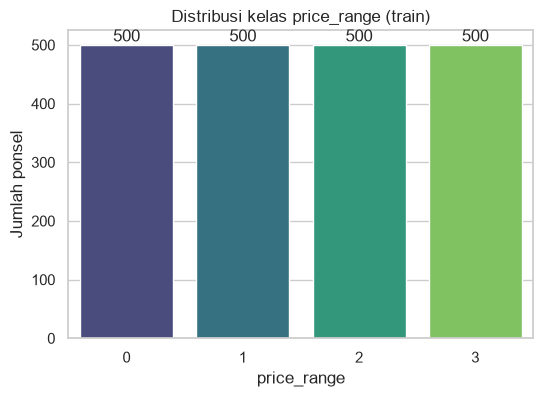

In [7]:
hitung = train[TARGET].value_counts().sort_index()
print(hitung)

plt.figure(figsize=(6, 4))
ax = sns.countplot(x=TARGET, data=train, palette="viridis")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Distribusi kelas price_range (train)")
plt.xlabel("price_range")
plt.ylabel("Jumlah ponsel")
plt.show()

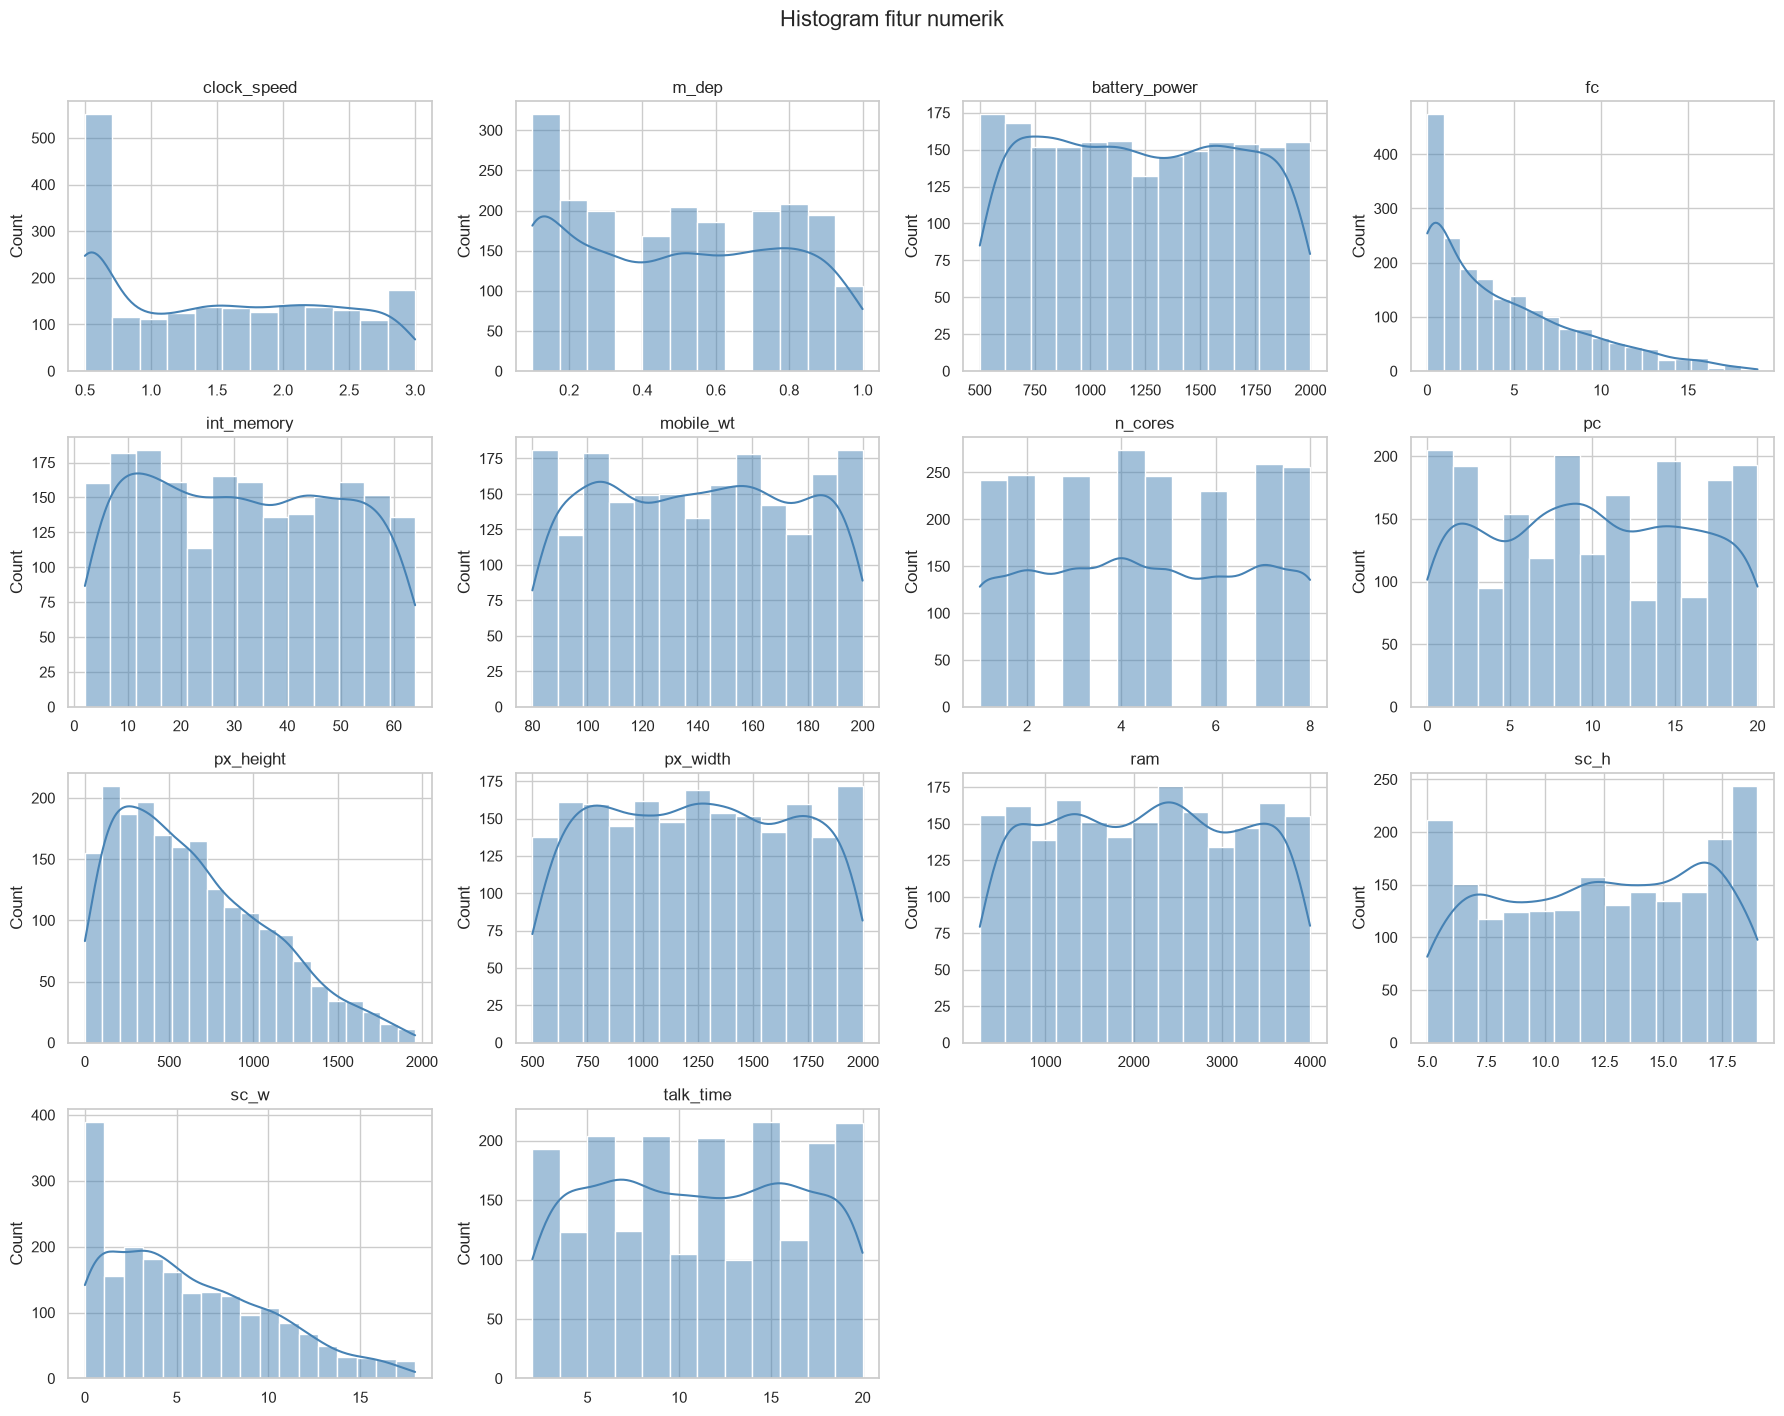

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.ravel(), fitur_numerik + [None, None]):
    if col is None:
        ax.axis("off")
        continue
    sns.histplot(train[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Histogram fitur numerik", y=1.01, fontsize=16)
plt.tight_layout()
plt.show()

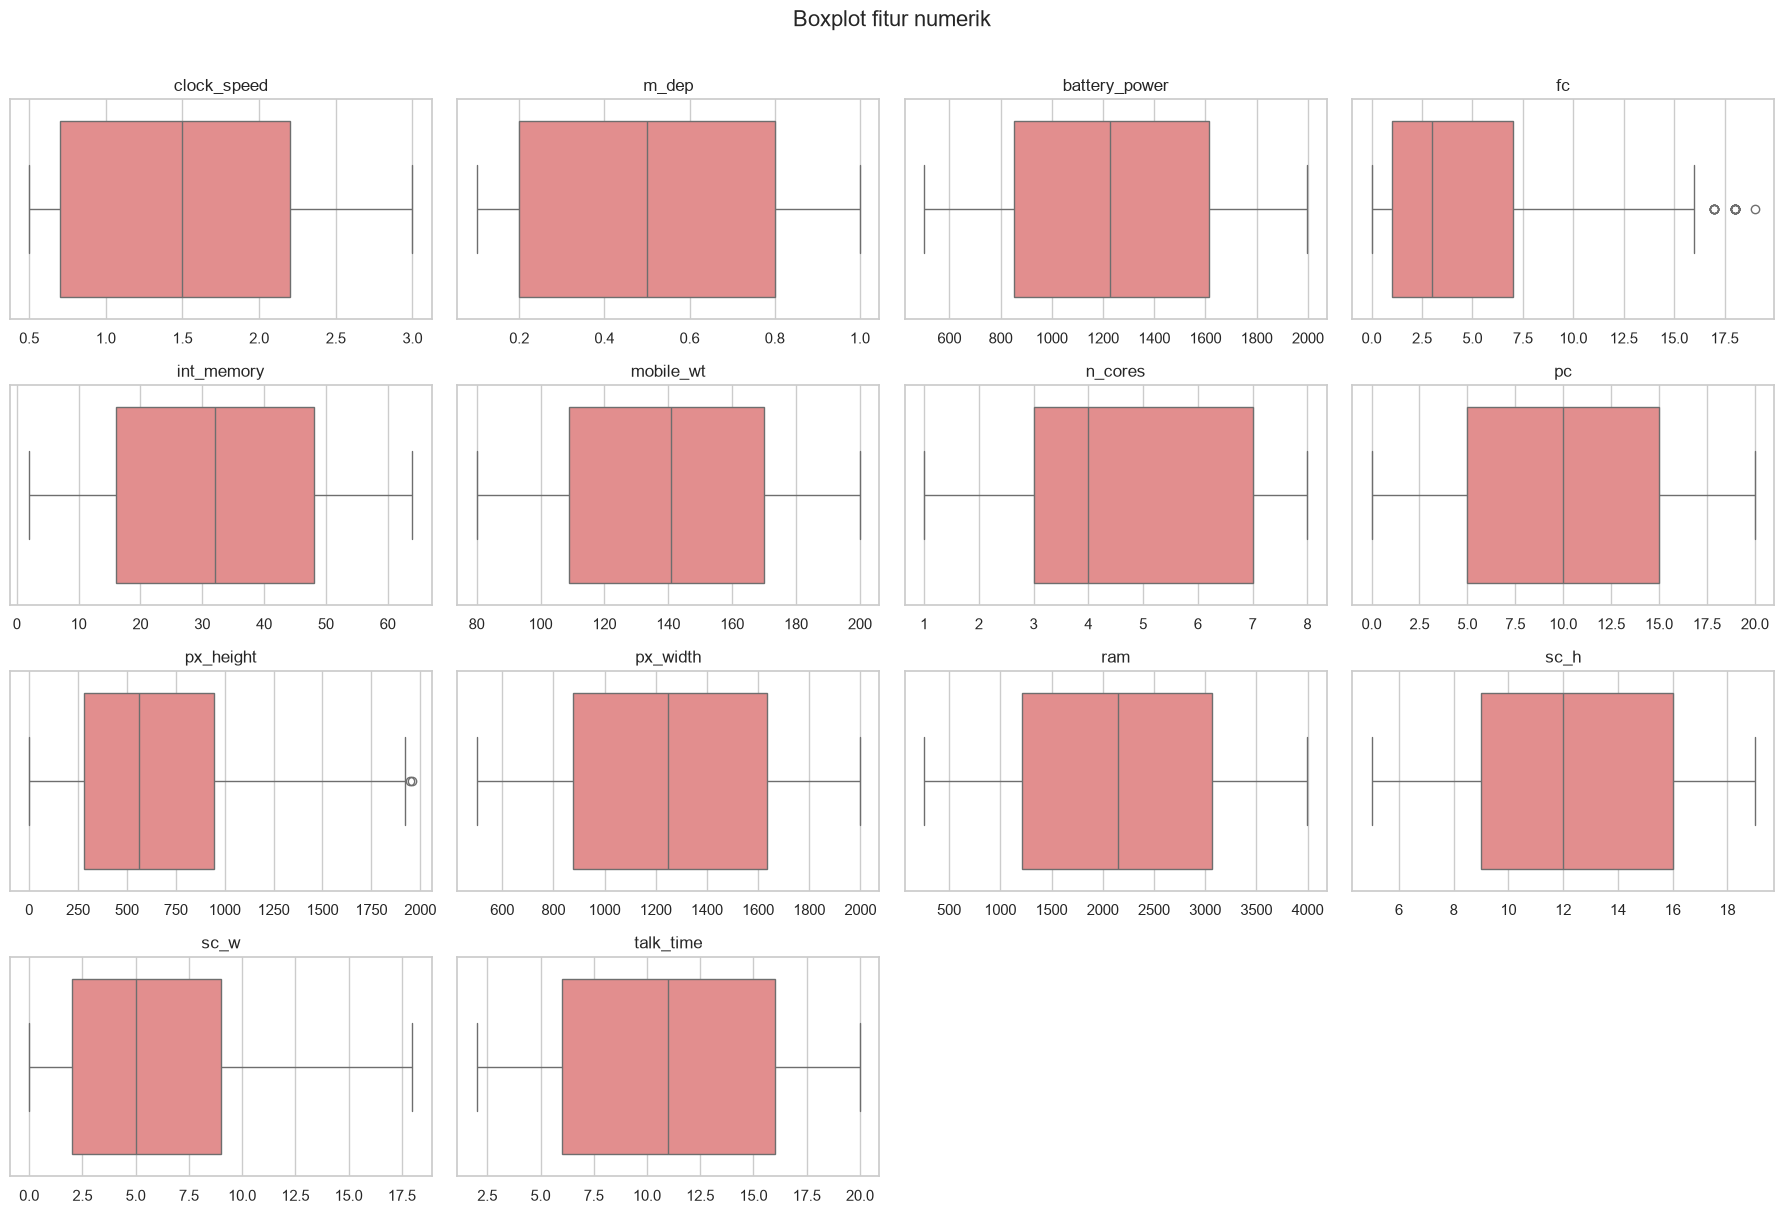

In [9]:
fig, axes = plt.subplots(4, 4, figsize=(18, 12))
for ax, col in zip(axes.ravel(), fitur_numerik + [None, None]):
    if col is None:
        ax.axis("off")
        continue
    sns.boxplot(x=train[col], ax=ax, color="lightcoral")
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Boxplot fitur numerik", y=1.01, fontsize=16)
plt.tight_layout()
plt.show()

In [10]:
# Outlier menurut aturan IQR
hasil = []
for col in fitur_numerik:
    q1, q3 = train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((train[col] < batas_bawah) | (train[col] > batas_atas)).sum()
    hasil.append([col, n_out])
outlier_df = pd.DataFrame(hasil, columns=["Fitur", "Jumlah outlier (IQR)"]).sort_values("Jumlah outlier (IQR)", ascending=False)
display(outlier_df)

# Nilai tidak wajar: secara fisik tidak mungkin bernilai 0
print("px_height = 0 -> train:", (train["px_height"] == 0).sum(), "| test:", (test["px_height"] == 0).sum())
print("sc_w      = 0 -> train:", (train["sc_w"] == 0).sum(), "| test:", (test["sc_w"] == 0).sum())

,Fitur,Jumlah outlier (IQR)
3,fc,18
8,px_height,2
1,m_dep,0
2,battery_power,0
4,int_memory,0
0,clock_speed,0
5,mobile_wt,0
6,n_cores,0
7,pc,0
9,px_width,0


px_height = 0 -> train: 2 | test: 2
sc_w      = 0 -> train: 180 | test: 112


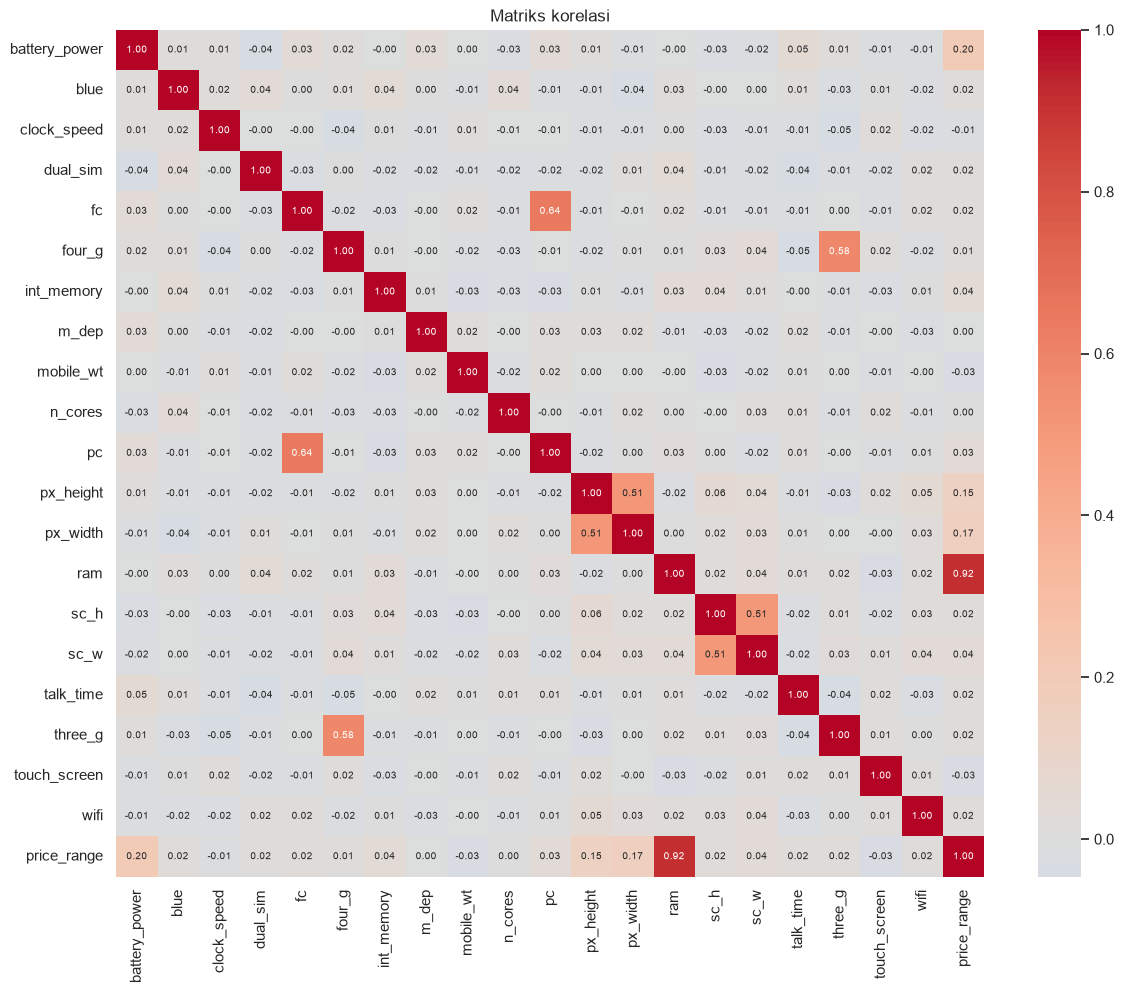

Korelasi fitur terhadap price_range (diurutkan):


,korelasi
ram,0.917046
battery_power,0.200723
px_width,0.165818
px_height,0.148858
int_memory,0.044435
sc_w,0.038711
pc,0.033599
three_g,0.023611
sc_h,0.022986
fc,0.021998


In [11]:
korelasi = train.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Matriks korelasi")
plt.show()

print("Korelasi fitur terhadap price_range (diurutkan):")
korelasi_target = korelasi[TARGET].drop(TARGET).sort_values(ascending=False)
display(korelasi_target.to_frame("korelasi"))

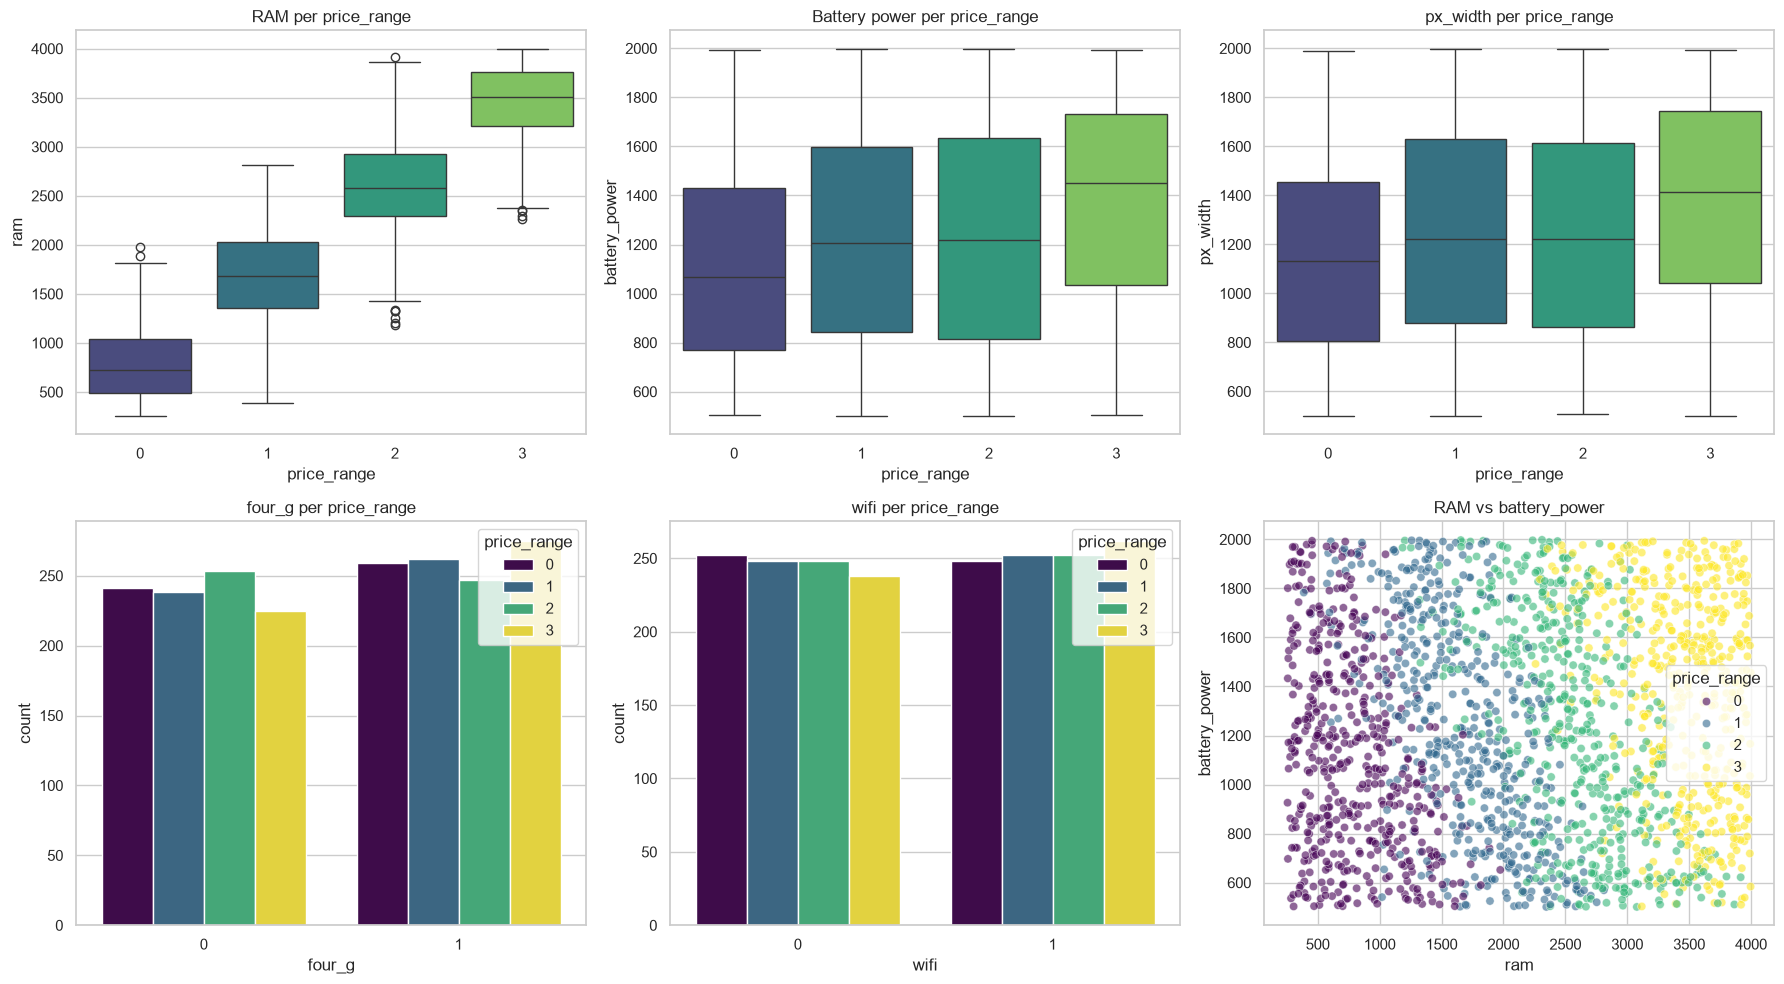

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.boxplot(x=TARGET, y="ram", data=train, palette="viridis", ax=axes[0, 0])
axes[0, 0].set_title("RAM per price_range")

sns.boxplot(x=TARGET, y="battery_power", data=train, palette="viridis", ax=axes[0, 1])
axes[0, 1].set_title("Battery power per price_range")

sns.boxplot(x=TARGET, y="px_width", data=train, palette="viridis", ax=axes[0, 2])
axes[0, 2].set_title("px_width per price_range")

sns.countplot(x="four_g", hue=TARGET, data=train, palette="viridis", ax=axes[1, 0])
axes[1, 0].set_title("four_g per price_range")

sns.countplot(x="wifi", hue=TARGET, data=train, palette="viridis", ax=axes[1, 1])
axes[1, 1].set_title("wifi per price_range")

sns.scatterplot(x="ram", y="battery_power", hue=TARGET, data=train, palette="viridis", alpha=0.6, ax=axes[1, 2])
axes[1, 2].set_title("RAM vs battery_power")

plt.tight_layout()
plt.show()

,mean_train,mean_test,std_train,std_test,selisih_mean_%
clock_speed,1.522,1.541,0.816,0.829,1.23
m_dep,0.502,0.518,0.288,0.281,3.14
battery_power,1238.518,1248.510,439.418,432.458,0.81
fc,4.310,4.593,4.341,4.463,6.58
int_memory,32.046,33.652,18.146,18.129,5.01
mobile_wt,140.249,139.511,35.400,34.852,-0.53
n_cores,4.520,4.328,2.288,2.288,-4.26
pc,9.916,10.054,6.064,6.095,1.39
px_height,645.108,627.121,443.781,432.930,-2.79
px_width,1251.516,1239.774,432.199,439.671,-0.94


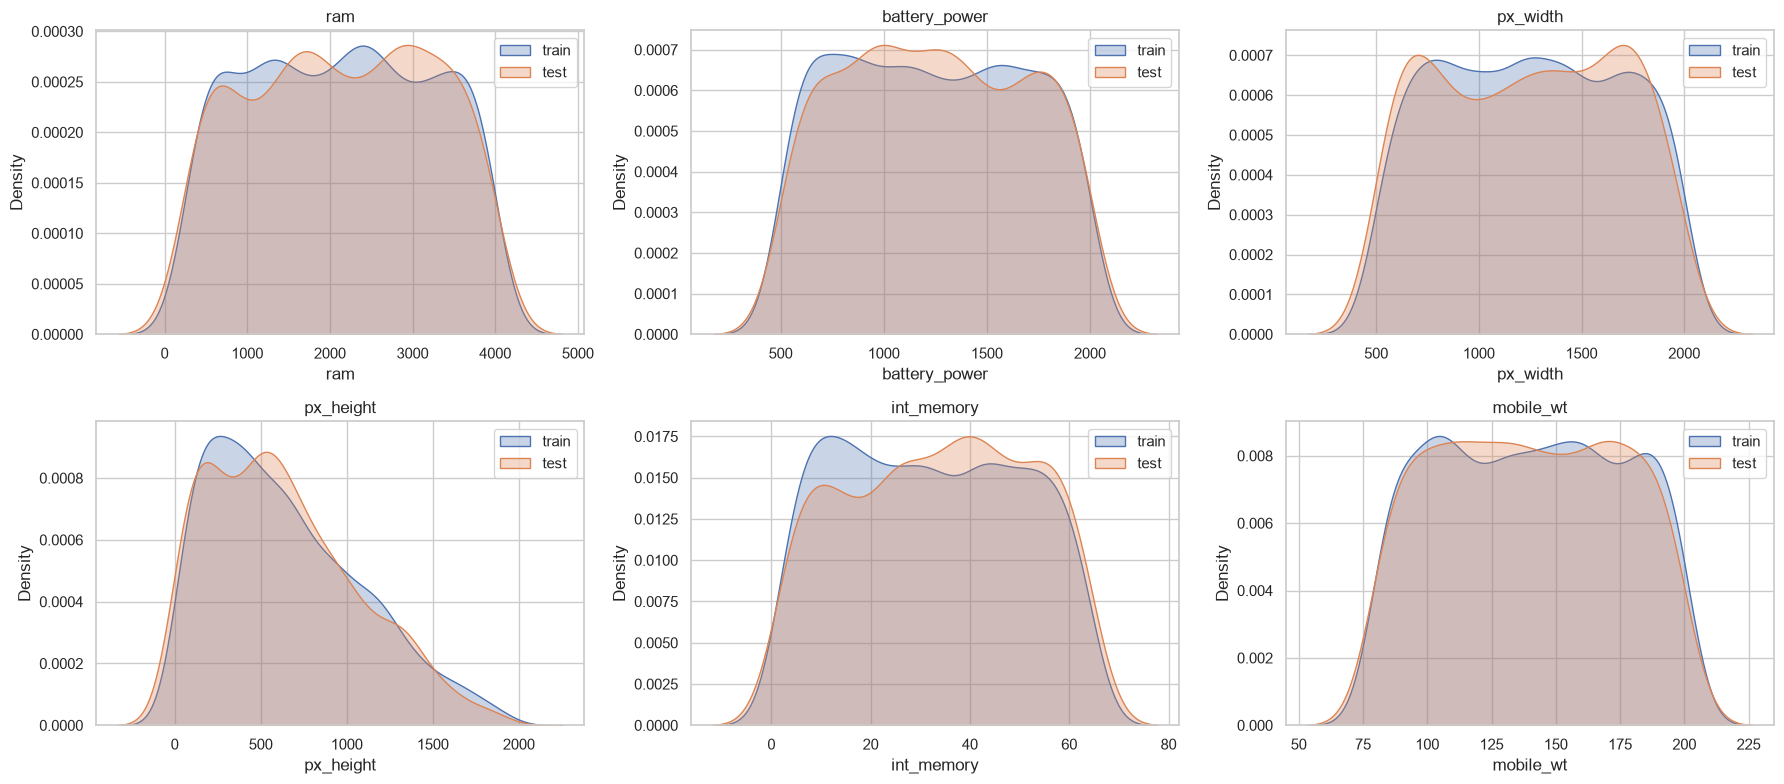

In [13]:
ringkas = pd.DataFrame({
    "mean_train": train[fitur_numerik].mean(),
    "mean_test": test[fitur_numerik].mean(),
    "std_train": train[fitur_numerik].std(),
    "std_test": test[fitur_numerik].std(),
})
ringkas["selisih_mean_%"] = ((ringkas["mean_test"] - ringkas["mean_train"]) / ringkas["mean_train"] * 100).round(2)
display(ringkas.round(3))

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axes.ravel(), ["ram", "battery_power", "px_width", "px_height", "int_memory", "mobile_wt"]):
    sns.kdeplot(train[col], label="train", ax=ax, fill=True, alpha=0.3)
    sns.kdeplot(test[col], label="test", ax=ax, fill=True, alpha=0.3)
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

In [14]:
# Tandai 0 pada px_height dan sc_w sebagai nilai hilang (NaN).
# Imputasi median dilakukan nanti, SETELAH pembagian data, supaya median hanya dihitung dari data latih.
kolom_tidak_wajar = ["px_height", "sc_w"]

train_clean = train.copy()
test_clean = test.copy()
for col in kolom_tidak_wajar:
    train_clean[col] = train_clean[col].replace(0, np.nan)
    test_clean[col] = test_clean[col].replace(0, np.nan)

print("Jumlah NaN hasil penandaan (train):")
print(train_clean[kolom_tidak_wajar].isnull().sum())
print("Jumlah NaN hasil penandaan (test):")
print(test_clean[kolom_tidak_wajar].isnull().sum())

Jumlah NaN hasil penandaan (train):
px_height      2
sc_w         180
dtype: int64
Jumlah NaN hasil penandaan (test):
px_height      2
sc_w         112
dtype: int64


In [15]:
X = train_clean.drop(columns=[TARGET])
y = train_clean[TARGET]

# Kolom id TIDAK dipakai sebagai fitur; simpan hanya untuk submission
test_id = test_clean["id"]
X_test = test_clean.drop(columns=["id"])

# Pastikan urutan kolom test sama dengan train
X_test = X_test[X.columns]

print("X:", X.shape, "| y:", y.shape, "| X_test:", X_test.shape)
print("Kolom id ikut jadi fitur?", "id" in X.columns or "id" in X_test.columns)

X: (2000, 20) | y: (2000,) | X_test: (1000, 20)
Kolom id ikut jadi fitur? False


In [16]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Data latih   :", X_train.shape)
print("Data validasi:", X_val.shape)
print("\nProporsi kelas data latih:\n", y_train.value_counts(normalize=True).sort_index())
print("Proporsi kelas data validasi:\n", y_val.value_counts(normalize=True).sort_index())

Data latih   : (1600, 20)
Data validasi: (400, 20)

Proporsi kelas data latih:
 price_range
0    0.25
1    0.25
2    0.25
3    0.25
Name: proportion, dtype: float64
Proporsi kelas data validasi:
 price_range
0    0.25
1    0.25
2    0.25
3    0.25
Name: proportion, dtype: float64


In [17]:
# Imputasi median: fit HANYA di data latih
imputer = SimpleImputer(strategy="median")
imputer.fit(X_train[kolom_tidak_wajar])
print("Median hasil imputasi (dari data latih):", dict(zip(kolom_tidak_wajar, imputer.statistics_)))

def impute_dan_rekayasa(df):
    df = df.copy()
    df[kolom_tidak_wajar] = imputer.transform(df[kolom_tidak_wajar])
    # Rekayasa fitur
    df["screen_area"] = df["sc_h"] * df["sc_w"]
    df["total_pixels"] = df["px_height"] * df["px_width"]
    return df

X_train = impute_dan_rekayasa(X_train)
X_val = impute_dan_rekayasa(X_val)
X_test = impute_dan_rekayasa(X_test)

print("\nSisa NaN -> latih/validasi/test:",
      X_train.isnull().sum().sum(), X_val.isnull().sum().sum(), X_test.isnull().sum().sum())
print("Jumlah fitur sekarang:", X_train.shape[1])

# Apakah fitur baru berguna? (korelasi dengan target pada data latih)
cek = X_train[["screen_area", "total_pixels"]].copy()
cek["price_range"] = y_train
print("\nKorelasi fitur baru dengan price_range:")
print(cek.corr()["price_range"].drop("price_range").round(3))

Median hasil imputasi (dari data latih): {'px_height': np.float64(567.0), 'sc_w': np.float64(5.0)}

Sisa NaN -> latih/validasi/test: 0 0 0
Jumlah fitur sekarang: 22

Korelasi fitur baru dengan price_range:
screen_area     0.042
total_pixels    0.166
Name: price_range, dtype: float64


In [18]:
# Fit scaler hanya pada data latih, lalu terapkan ke validasi dan test (tanpa data leakage)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print("Rata-rata data latih setelah scaling (harus ~0):", X_train_s.mean().round(4))
print("Std data latih setelah scaling (harus ~1)     :", X_train_s.std().round(4))

Rata-rata data latih setelah scaling (harus ~0): 0.0
Std data latih setelah scaling (harus ~1)     : 1.0


In [19]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(random_state=RANDOM_STATE),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baris = []
for nama, model in models.items():
    model.fit(X_train_s, y_train)
    acc_train = accuracy_score(y_train, model.predict(X_train_s))
    acc_val = accuracy_score(y_val, model.predict(X_val_s))

    # Cross-validation dengan Pipeline: scaler di-fit ulang di tiap fold (aman dari leakage)
    pipa = Pipeline([("scaler", StandardScaler()), ("model", model)])
    cv = cross_val_score(pipa, X_train, y_train, cv=skf, scoring="accuracy")

    baris.append([nama, acc_train, acc_val, cv.mean(), cv.std()])

hasil_model = pd.DataFrame(baris, columns=["Model", "Akurasi Latih", "Akurasi Validasi", "CV Mean (5-fold)", "CV Std"])
hasil_model = hasil_model.sort_values("CV Mean (5-fold)", ascending=False).reset_index(drop=True)
display(hasil_model.round(4))

,Model,Akurasi Latih,Akurasi Validasi,CV Mean (5-fold),CV Std
0,Logistic Regression,0.9762,0.9625,0.9481,0.0102
1,Random Forest,1.0000,0.8850,0.8719,0.0295
2,SVM (RBF),0.9812,0.8625,0.8531,0.0091
3,Decision Tree,1.0000,0.8650,0.8438,0.0099
4,KNN,0.6981,0.4975,0.4825,0.0260


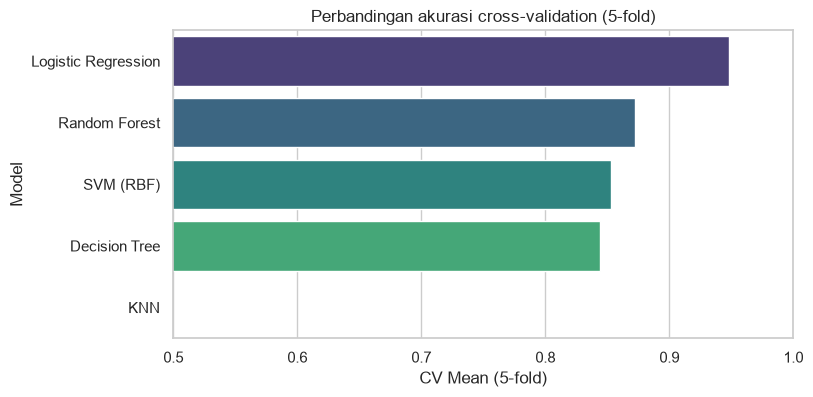

In [20]:
plt.figure(figsize=(8, 4))
sns.barplot(x="CV Mean (5-fold)", y="Model", data=hasil_model, palette="viridis")
plt.xlim(0.5, 1.0)
plt.title("Perbandingan akurasi cross-validation (5-fold)")
plt.show()

In [21]:
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10, 100]},
    "KNN": {"model__n_neighbors": [3, 5, 7, 9, 11, 15], "model__weights": ["uniform", "distance"]},
    "Decision Tree": {"model__max_depth": [3, 5, 7, 10, None], "model__min_samples_split": [2, 5, 10]},
    "Random Forest": {"model__n_estimators": [100, 300], "model__max_depth": [None, 10, 20], "model__min_samples_split": [2, 5]},
    "SVM (RBF)": {"model__C": [0.1, 1, 10, 100], "model__gamma": ["scale", 0.01, 0.1]},
}

model_terbaik_nama = hasil_model.loc[0, "Model"]
print("Model terbaik berdasarkan CV:", model_terbaik_nama)

pipa_terbaik = Pipeline([("scaler", StandardScaler()), ("model", models[model_terbaik_nama])])
grid = GridSearchCV(pipa_terbaik, param_grids[model_terbaik_nama], cv=skf, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print("Parameter terbaik:", grid.best_params_)
print("Akurasi CV terbaik:", round(grid.best_score_, 4))

model_final = grid.best_estimator_

Model terbaik berdasarkan CV: Logistic Regression
Parameter terbaik: {'model__C': 100}
Akurasi CV terbaik: 0.9619


,Fitur,Importance
13,ram,0.7055
0,battery_power,0.2330
12,px_width,0.1277
11,px_height,0.1150
20,screen_area,0.0240
21,total_pixels,0.0235
8,mobile_wt,0.0207
15,sc_w,0.0072
6,int_memory,0.0067
14,sc_h,0.0055


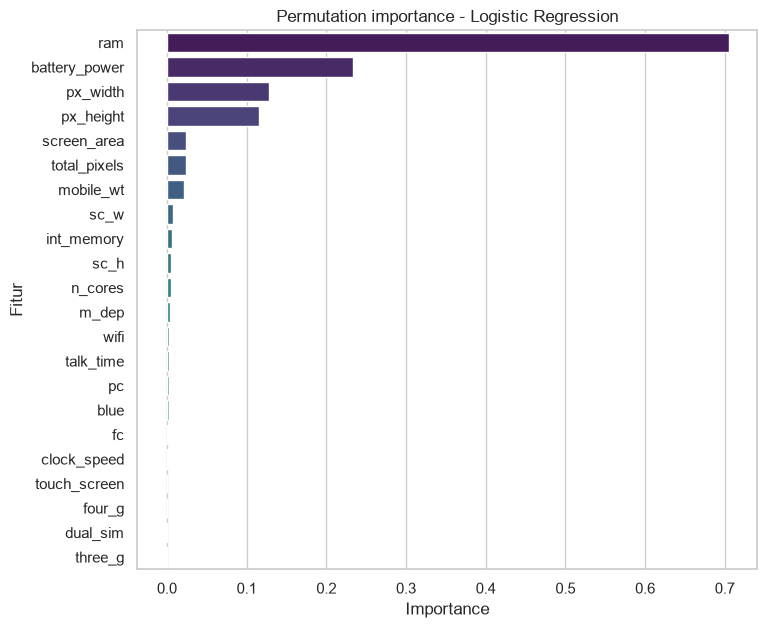

In [22]:
# Feature importance dengan permutation importance (bisa dipakai untuk semua jenis model)
pi = permutation_importance(model_final, X_val, y_val, n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
fi = pd.DataFrame({"Fitur": X_val.columns, "Importance": pi.importances_mean}).sort_values("Importance", ascending=False)
display(fi.head(10).round(4))

plt.figure(figsize=(8, 7))
sns.barplot(x="Importance", y="Fitur", data=fi, palette="viridis")
plt.title(f"Permutation importance - {model_terbaik_nama}")
plt.show()

In [23]:
y_val_pred = model_final.predict(X_val)
y_train_pred = model_final.predict(X_train)

print("Akurasi validasi:", round(accuracy_score(y_val, y_val_pred), 4))
print()
print(classification_report(y_val, y_val_pred, digits=4))

Akurasi validasi: 0.98

              precision    recall  f1-score   support

           0     0.9901    1.0000    0.9950       100
           1     1.0000    0.9500    0.9744       100
           2     0.9429    0.9900    0.9659       100
           3     0.9899    0.9800    0.9849       100

    accuracy                         0.9800       400
   macro avg     0.9807    0.9800    0.9800       400
weighted avg     0.9807    0.9800    0.9800       400



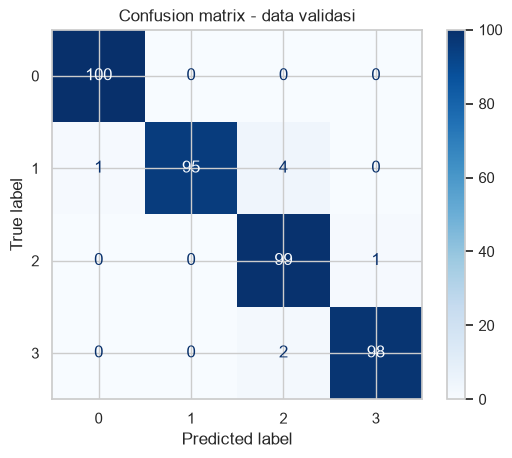

Kesalahan paling sering:
  asli 1 -> prediksi 2 : 4 ponsel
  asli 3 -> prediksi 2 : 2 ponsel
  asli 1 -> prediksi 0 : 1 ponsel
  asli 2 -> prediksi 3 : 1 ponsel


In [24]:
cm = confusion_matrix(y_val, y_val_pred)
ConfusionMatrixDisplay(cm, display_labels=[0, 1, 2, 3]).plot(cmap="Blues")
plt.title("Confusion matrix - data validasi")
plt.show()

# Pasangan kelas yang paling sering tertukar
tertukar = []
for i in range(4):
    for j in range(4):
        if i != j and cm[i, j] > 0:
            tertukar.append((f"asli {i} -> prediksi {j}", cm[i, j]))
tertukar = sorted(tertukar, key=lambda t: -t[1])
print("Kesalahan paling sering:")
for k, v in tertukar[:5]:
    print(" ", k, ":", v, "ponsel")

In [25]:
acc_train = accuracy_score(y_train, y_train_pred)
acc_val = accuracy_score(y_val, y_val_pred)
print(f"Akurasi latih    : {acc_train:.4f}")
print(f"Akurasi validasi : {acc_val:.4f}")
print(f"Selisih          : {acc_train - acc_val:.4f}")

Akurasi latih    : 0.9888
Akurasi validasi : 0.9800
Selisih          : 0.0088


In [26]:
pred_test = model_final.predict(X_test)

submission = pd.DataFrame({"id": test_id, "price_range": pred_test})
submission.to_csv("submission.csv", index=False)

print("submission.csv tersimpan:", submission.shape)
display(submission.head())
print("\nSebaran prediksi pada test:")
print(submission["price_range"].value_counts().sort_index())

submission.csv tersimpan: (1000, 2)


,id,price_range
0,1,3
1,2,3
2,3,2
3,4,3
4,5,1



Sebaran prediksi pada test:
price_range
0    248
1    235
2    261
3    256
Name: count, dtype: int64
